# Visualizing IMSTE embeddings with MNIST

This notebook is a gallery of the public helpers in `imste.visualization`. It fits one two-dimensional IMSTE embedding on all 60,000 MNIST training images, then reuses the same coordinates throughout so the plots are directly comparable.

The cells save publication-ready PNGs to `docs/images/`, which are embedded in the companion [visualization guide](../docs/visualization-guide.md). The interactive cell opens a live widget in Jupyter.

Install the notebook dependencies from the repository root with `python -m pip install ".[notebook]"`.

## 1. Load the full MNIST training set

The repository cache is used when present. Otherwise, scikit-learn downloads MNIST from OpenML and caches it locally. We use all 60,000 training rows, scale the pixel features, and keep the labels separate from the embedding fit.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

ROOT = next(parent for parent in (Path.cwd(), *Path.cwd().parents)
            if (parent / "imste").is_dir() and (parent / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler

from imste import IteratedMinimumSpanningTreeEmbedder
from imste.visualization import (
    cross_validate_embedding_knn,
    interactive_force,
    plot_class_mixture_mst,
    plot_density_parent_tree,
    plot_ellipses,
    plot_embedding,
    plot_knn_union,
    render_datashader_embedding,
)

# Keep generated images in the checkout.
IMAGE_DIR = ROOT / "docs" / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

cache_file = ROOT / "data" / "mnist" / "cache" / "mnist_784_v1.npz"
if cache_file.exists():
    with np.load(cache_file) as cache:
        X_all = cache["features"].astype(np.float32)
        y_all = cache["labels"].astype(np.int64)
else:
    mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff", cache=True)
    X_all = np.asarray(mnist.data, dtype=np.float32)
    y_all = np.asarray(mnist.target, dtype=np.int64)

X = StandardScaler().fit_transform(X_all[:60_000]).astype(np.float32)
y = y_all[:60_000]
obs = pd.DataFrame({"digit": y})
print(f"Using all {len(y):,} MNIST training images, each with {X.shape[1]} pixel features.")

Using all 60,000 MNIST training images, each with 784 pixel features.


## 2. Fit one embedding

This fit uses only the standardized pixel matrix. The digit labels are reserved for coloring and evaluating the visualizations.

In [2]:
mapper = IteratedMinimumSpanningTreeEmbedder(
    n_msts=64,
    n_epochs=900,
    mst_neighbors=15,
    gravity_strength=0.2,
    mean_shift_iterations=3,
    random_state=42,
    device="auto",
)
Z = mapper.fit_transform(X)
print(f"Embedding shape: {Z.shape}; optimizer device: {mapper.device_}")

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 180, "font.size": 10})

def save_figure(fig, filename):
    fig.savefig(IMAGE_DIR / filename, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

Embedding shape: (60000, 2); optimizer device: mps


## 3. `plot_embedding`: the baseline view

A clean scatter plot is the reference for the specialized renderers below.

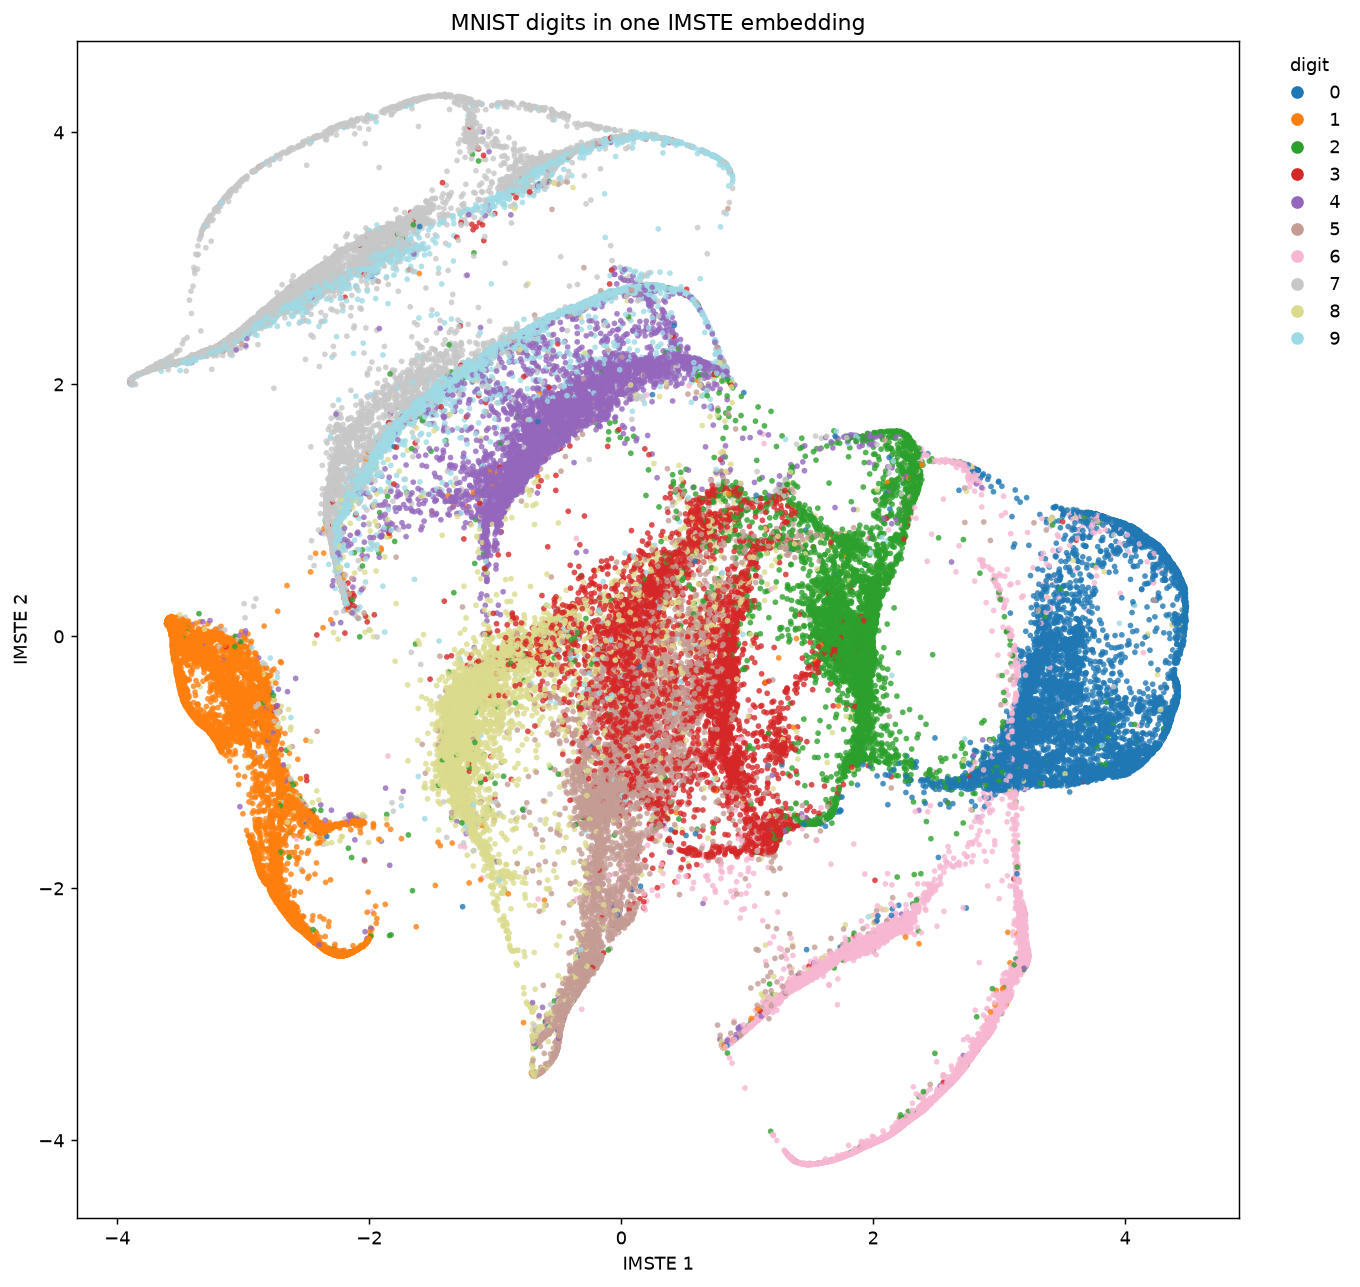

In [3]:
fig, axes = plot_embedding(Z, obs, label_key="digit", point_size=10, point_alpha=0.8)
ax = np.asarray(axes).reshape(-1)[0]
ax.set_title("MNIST digits in one IMSTE embedding")
save_figure(fig, "visualization-embedding.png")

## 4. `render_datashader_embedding`: rasterized density and labels

Datashader is useful when points overlap heavily. It returns a raster image that can be displayed directly or converted to a PIL image for saving.

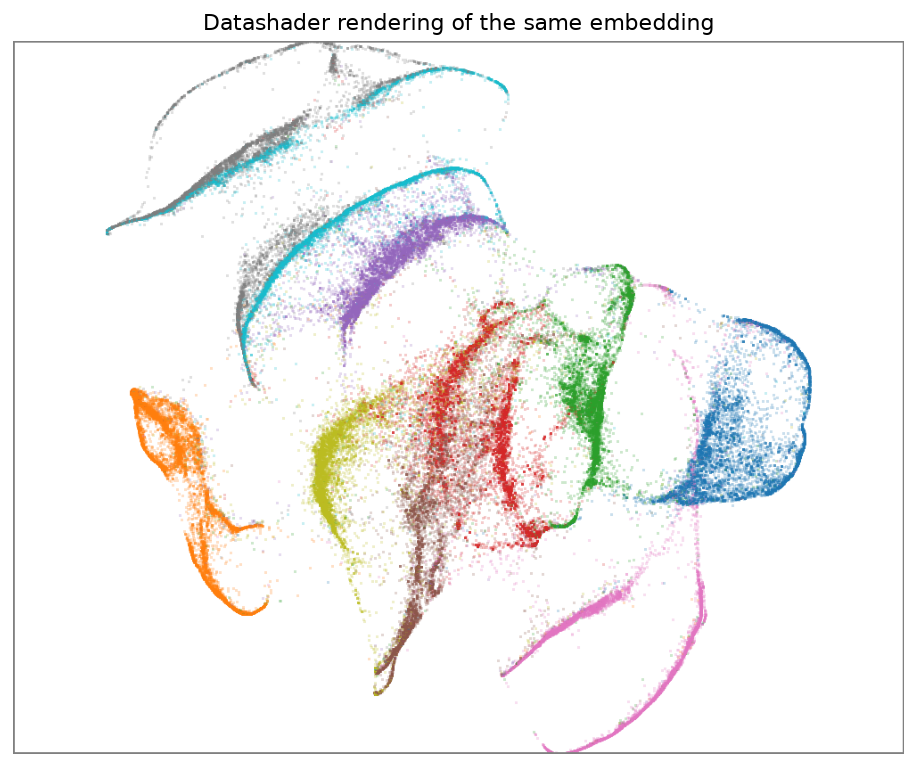

In [4]:
raster = render_datashader_embedding(
    Z, obs, label_key="digit", width=1000, height=800,
    preserve_aspect=True, how="eq_hist", spread_px=1, min_alpha=60,
)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(raster.to_pil())
ax.set_title("Datashader rendering of the same embedding")
ax.set_axis_off()
fig.tight_layout()
save_figure(fig, "visualization-datashader.png")

## 5. `plot_knn_union`: same-digit neighborhoods

This renderer outlines the union of cross-validated, same-label k-nearest-neighbor regions. It emphasizes where each digit forms coherent local neighborhoods.

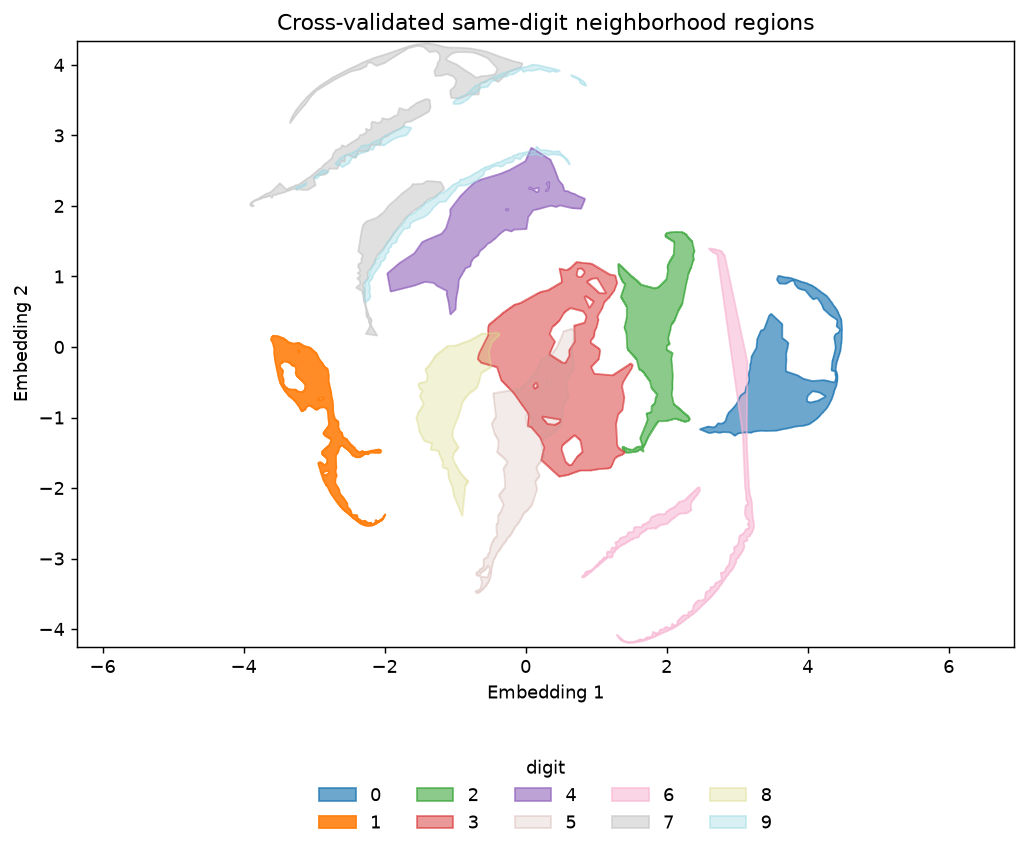

In [5]:
fig, ax = plot_knn_union(
    Z, obs, label_key="digit", k=30, cv_neighbors=5, cv_splits=5,
    random_state=42, legend_position="bottom",
)
ax.set_title("Cross-validated same-digit neighborhood regions")
save_figure(fig, "visualization-knn-union.png")

## 6. `plot_ellipses`: compact class regions

Ellipses summarize selected local regions for each digit. They are a compact guide to spread and overlap, not a boundary classifier.

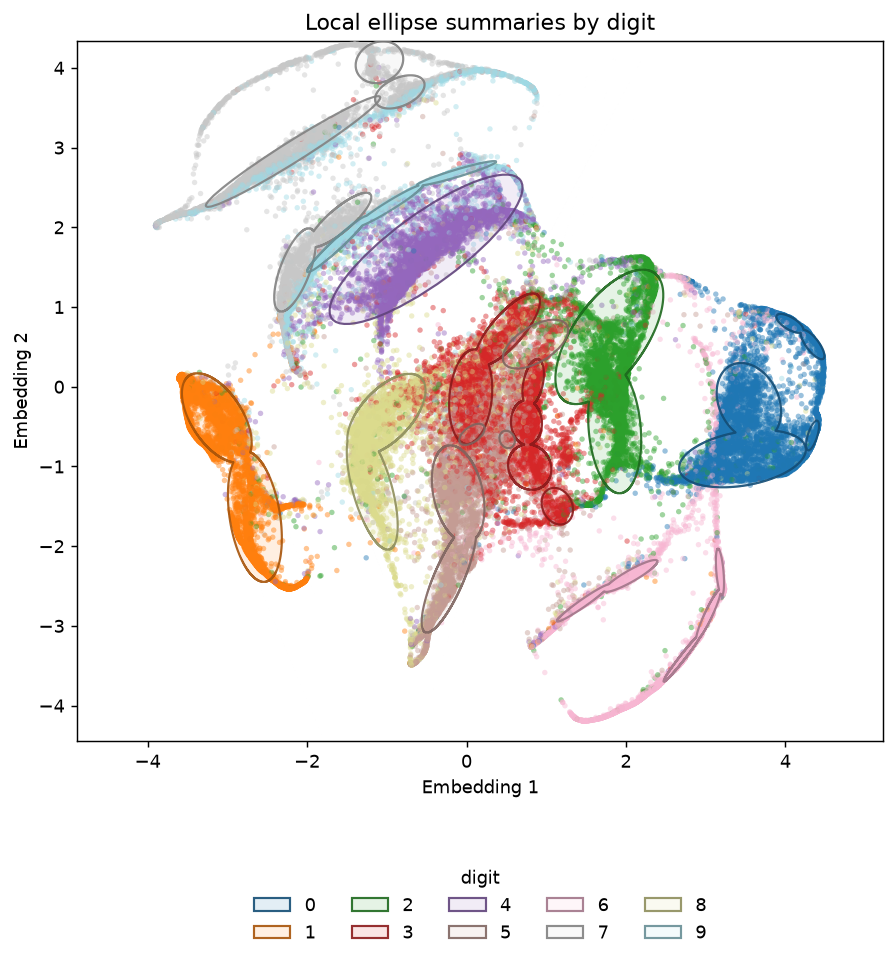

In [6]:
fig, ax = plot_ellipses(
    Z, obs, label_key="digit", k=5, cv_neighbors=5, cv_splits=5,
    random_state=42, point_size=9, point_alpha=0.45, min_ellipse_area=0.03, 
    legend_position="bottom",
)
ax.set_title("Local ellipse summaries by digit")
save_figure(fig, "visualization-ellipses.png")

## 7. `plot_density_parent_tree`: connect density peaks

The density-parent graph links points toward nearby higher-density points. Its exact KDE is quadratic in sample count, so this view uses a fixed 5,000-point sample from the full fitted embedding. Different-label links are faded so the topology can be inspected alongside the known digit labels.

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


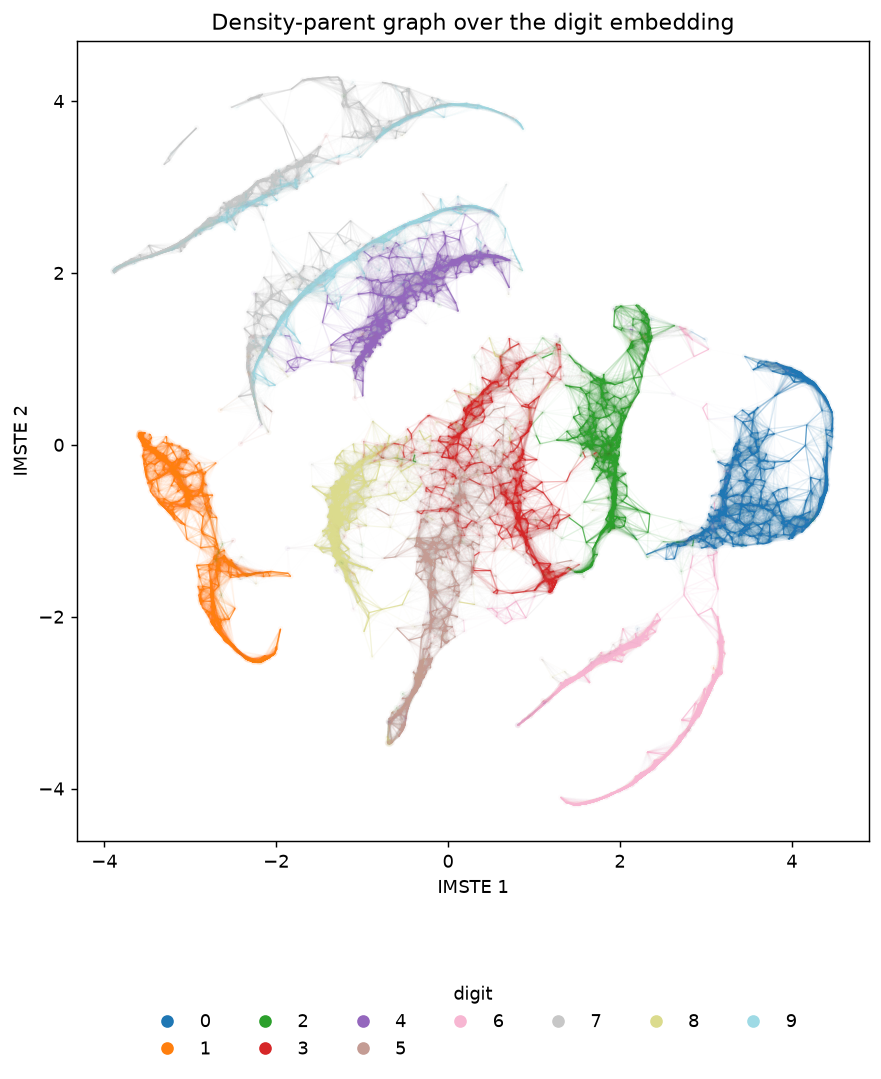

In [7]:
tree_rng = np.random.default_rng(42)
tree_indices = np.sort(tree_rng.choice(len(Z), size=5_000, replace=False))
fig, ax = plot_density_parent_tree(
    Z[tree_indices], obs.iloc[tree_indices], label_key="digit", k=30, point_size=9,
    point_alpha=0.05, edge_alpha=0.75, cross_label_edge_alpha=0.08,
    legend_position="bottom",
)
ax.set_title("Density-parent graph over the digit embedding")
save_figure(fig, "visualization-density-parent-tree.png")

## 8. `plot_class_mixture_mst`: connect class components

This view fits small Gaussian mixtures within each digit, then draws iterated MST links between mixture components. Line opacity indicates the estimated cross-class overlap. The returned table contains the per-edge overlap scores.

Class graph edges: 31


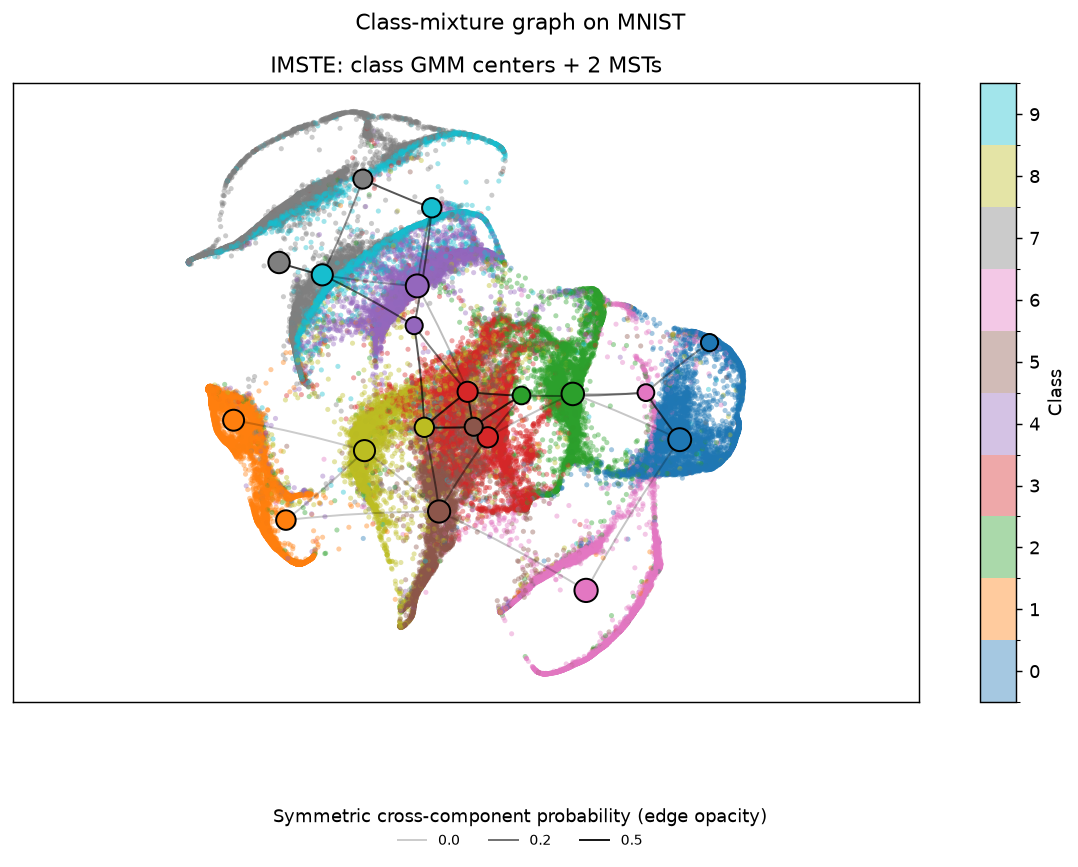

,embedding,class_a,component_a,class_b,component_b,mst_rank,component_a_posterior_on_b,component_b_posterior_on_a,symmetric_component_overlap,edge_alpha
0,IMSTE,0,0,6,1,1,0.327800,0.285274,0.306537,0.629152
1,IMSTE,6,1,2,0,1,0.106461,0.035985,0.071223,0.299712
2,IMSTE,2,1,3,0,1,0.175160,0.116648,0.145904,0.404265
3,IMSTE,3,0,5,0,1,0.328824,0.256123,0.292474,0.609463
4,IMSTE,5,0,3,1,1,0.413198,0.432944,0.423071,0.792300


In [8]:
fig, axes, class_edges = plot_class_mixture_mst(
    X, y, {"IMSTE": Z}, title="Class-mixture graph on MNIST",
    n_msts=2, max_components_per_class=2,
    min_component_size=12, random_state=42,
)
print(f"Class graph edges: {len(class_edges)}")
save_figure(fig, "visualization-class-mixture-mst.png")
class_edges.head()

## 9. `interactive_force`: explore label-guided adjustments

The widget exposes controls for same-label attraction, different-label repulsion, neighborhood size, and movement interpolation. It is an exploratory adjustment of the existing embedding; the labels do not enter the original IMSTE fit. Run this cell in Jupyter to interact with the live controls.

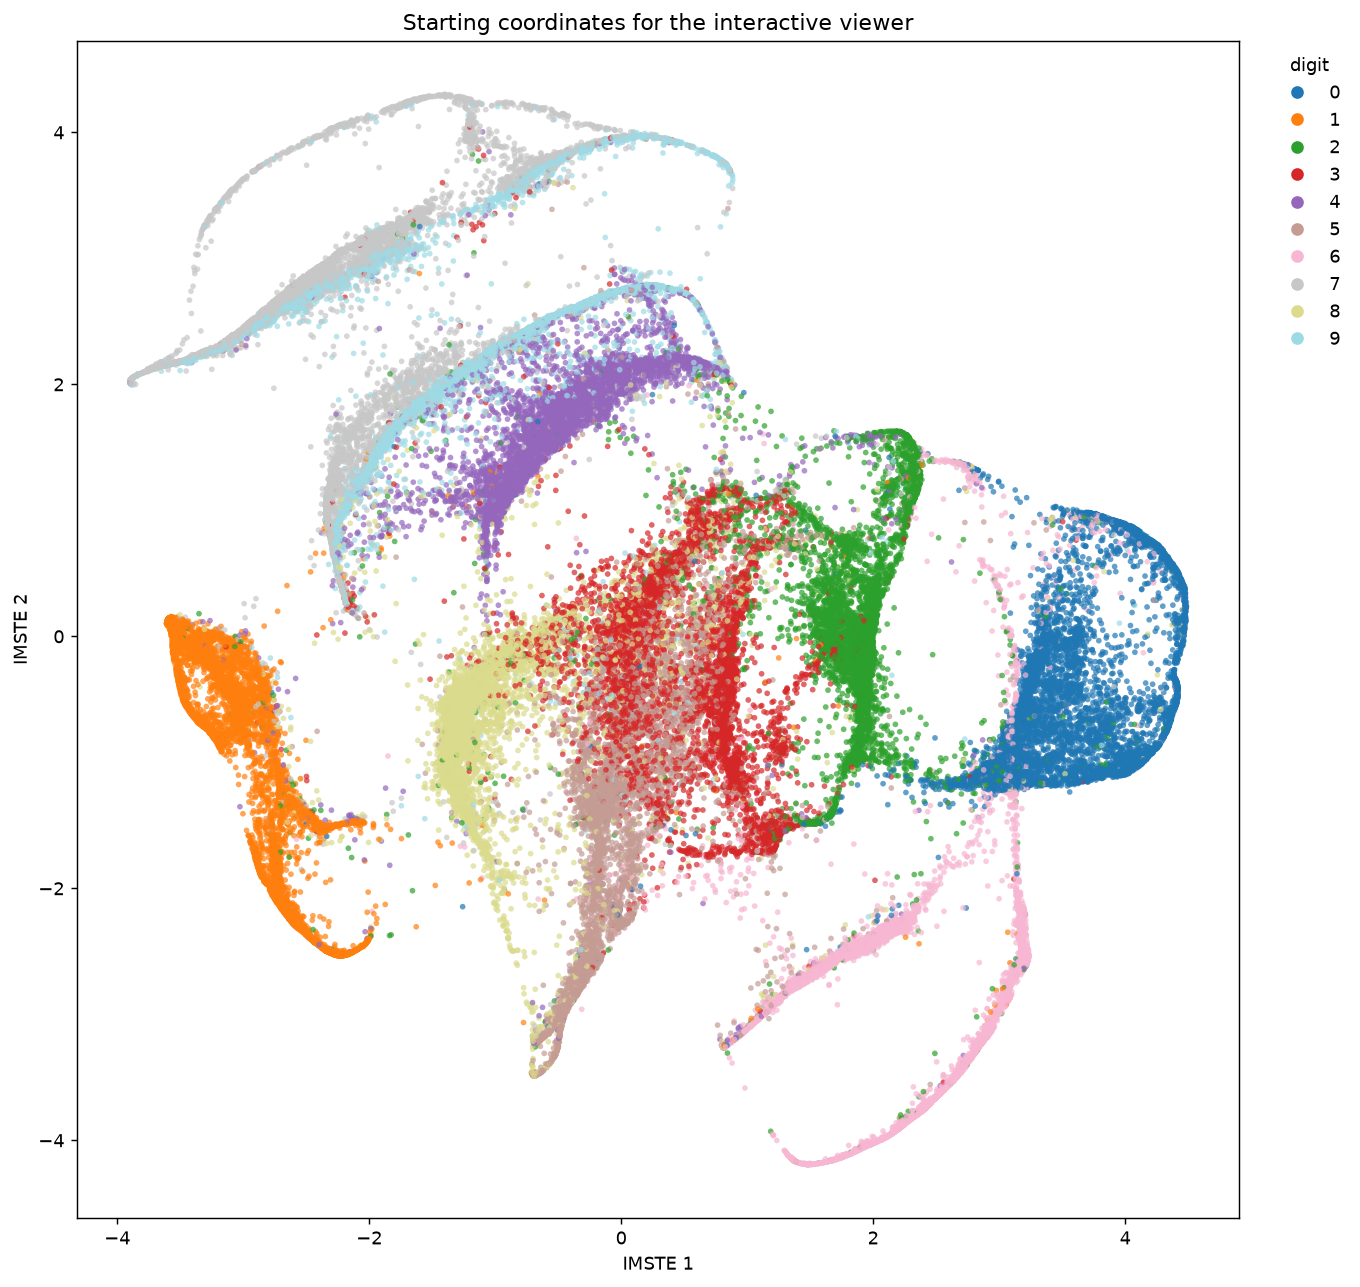

In [9]:
fig, axes = plot_embedding(Z, obs, label_key="digit", point_size=10, point_alpha=0.7)
ax = np.asarray(axes).reshape(-1)[0]
ax.set_title("Starting coordinates for the interactive viewer")
save_figure(fig, "visualization-interactive-force.png")

In [10]:
interactive_force(
    Z, obs, label_key="digit", initial_k=8, initial_iterations=30,
    initial_distance_fraction=0.3, max_k=30, max_iterations=120,
    point_size=9,
)

## 10. `cross_validate_embedding_knn`: quantify label separation

This public helper returns metrics and predictions rather than a plot. Here we summarize its confusion matrix to complement the visual inspection. Accuracy measures ordinary performance; balanced accuracy weights each digit equally.

5-NN accuracy: 0.846  |  balanced accuracy: 0.843  |  folds: 5


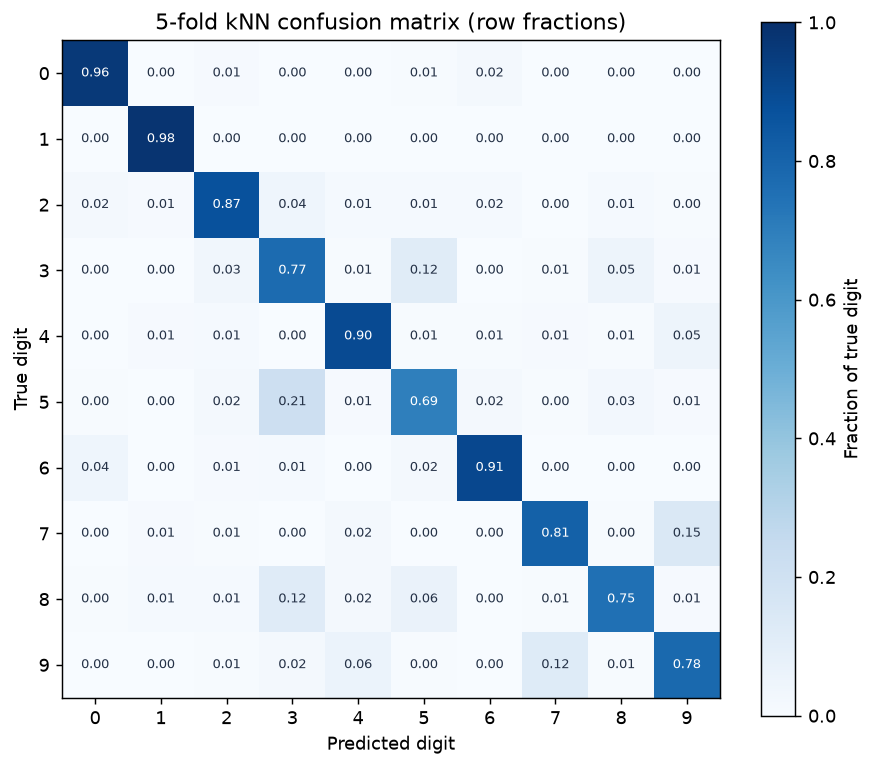

In [11]:
cv = cross_validate_embedding_knn(
    Z, obs, label_key="digit", n_neighbors=5, n_splits=5, random_state=42
)
print(
    f"5-NN accuracy: {cv['accuracy']:.3f}  |  "
    f"balanced accuracy: {cv['balanced_accuracy']:.3f}  |  "
    f"folds: {cv['n_splits']}"
)

confusion = cv["confusion_matrix"]
row_fractions = confusion / confusion.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(row_fractions, cmap="Blues", vmin=0, vmax=1)
ax.set(title="5-fold kNN confusion matrix (row fractions)",
       xlabel="Predicted digit", ylabel="True digit",
       xticks=np.arange(10), yticks=np.arange(10))
for row in range(10):
    for col in range(10):
        ax.text(col, row, f"{row_fractions[row, col]:.2f}",
                ha="center", va="center", fontsize=7,
                color="white" if row_fractions[row, col] > 0.55 else "#253247")
fig.colorbar(image, ax=ax, label="Fraction of true digit")
fig.tight_layout()
save_figure(fig, "visualization-knn-cross-validation.png")

## What each helper answers

- **Embedding scatter:** where are the labeled samples?
- **Datashader:** what patterns remain visible when many points overlap?
- **kNN union:** where do same-label local neighborhoods form?
- **Ellipses:** what compact local regions summarize each class?
- **Density-parent tree:** how are observations connected through density peaks?
- **Class-mixture MST:** how do class components relate, and where do they overlap?
- **Interactive force:** how does a controlled label-guided adjustment change a layout?
- **Cross-validated kNN:** how predictable are labels from the 2D coordinates?

All figures use the same 60,000-image training set and the same fitted embedding except the class-mixture graph, which uses the original pixel features to fit its within-class mixtures and uses `Z` for the displayed geometry.